# Phase 11: Final Analysis, Synthesis, and Project Reporting

## Executive Summary & Research Synthesis
This notebook provides the capstone analysis and final synthesis for the entire Chi-Square Machine Learning Statistics Project. 

Across Phases 0 through 10, we examined the theoretical and empirical consequences of reducing the cardinality of a high-cardinality categorical feature (`OCCP` — Occupation Code) in the US Census ACSIncome dataset ($N = 192,755$).

### Core Pipeline Milestones Covered:
1. **Phase 0–3**: Reproducible environment, exploratory data analysis, data cleaning, target binarization (`income_above_50k`), and stratified train/test partitioning ($80/20$).
2. **Phase 4**: High-cardinality profiling identifying `OCCP` as the maximum-cardinality feature with 529 unique categories.
3. **Phase 5**: Baseline contingency table construction and $\chi^2$ independence testing, revealing severe Cochran rule violations ($5.67\%$ of cells with $E_{ij} < 5$).
4. **Phase 6–8**: Frequency-based cardinality reduction ($N_{\text{min}} = 100$), transforming 271 sparse occupations into `'Rare'`, eliminating all low expected counts ($0.00\%$ violations), and strictly applying the mapping out-of-sample to test data.
5. **Phase 9–10**: Downstream machine learning evaluation using Logistic Regression with One-Hot Encoding, benchmarking Model A (Original OCCP, 813 features) against Model B (Grouped OCCP, 543 features) on both the full test set and the rare/unseen category subset.

In [1]:
# Setup and imports
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 1. Load and Display Historical Phase Results

In [2]:
# 1. Load all required result files
df_baseline_chi2 = pd.read_csv('../results/05_baseline_chi_square_results.csv')
df_transformed_chi2 = pd.read_csv('../results/07_transformed_chi_square_results.csv')
df_chi2_comp = pd.read_csv('../results/07_chi_square_before_after_comparison.csv')
df_model_comp = pd.read_csv('../results/09_model_comparison.csv')
df_gen_results = pd.read_csv('../results/10_generalization_results.csv')
df_rare_summary = pd.read_csv('../results/10_rare_unseen_category_summary.csv')

print("=== 1. Baseline Chi-Square Results (05) ===")
display(df_baseline_chi2)

print("\n=== 2. Transformed Chi-Square Results (07) ===")
display(df_transformed_chi2)

print("\n=== 3. Chi-Square Before vs. After Comparison (07) ===")
display(df_chi2_comp)

print("\n=== 4. Model Comparison Results (09) ===")
display(df_model_comp)

print("\n=== 5. Generalization Results (10) ===")
display(df_gen_results)

print("\n=== 6. Rare and Unseen Category Summary (10) ===")
display(df_rare_summary)

=== 1. Baseline Chi-Square Results (05) ===


,Number of categories,Chi-square statistic,Degrees of freedom,p-value,Number of cells with expected count below 5,Percentage of cells with expected count below 5,Number of categories with fewer than 10 observations,Number of categories with fewer than 50 observations,Number of categories with fewer than 100 observations
0,529,51535.8043,528,0.0,60,5.6711,23,172,271



=== 2. Transformed Chi-Square Results (07) ===


,Number of transformed categories,Chi-square statistic,Degrees of freedom,p-value,Number of cells with expected count below 5,Percentage of cells with expected count below 5,Number of categories with fewer than 10 observations,Number of categories with fewer than 50 observations
0,259,48444.0265,258,0.0,0,0.0,0,0



=== 3. Chi-Square Before vs. After Comparison (07) ===


...

,Model name,Number of features,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training time (seconds),Prediction time (seconds)
0,Model A (Original),813,0.7968,0.7597,0.7480,0.7538,0.8750,1.2313,0.0441
1,Model B (Transformed),543,0.7941,0.7548,0.7477,0.7512,0.8726,0.8659,0.0403



=== 5. Generalization Results (10) ===


,Evaluation subset,Model name,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Full test set,Model A (Original),0.7968,0.7597,0.7480,0.7538,0.8750
1,Full test set,Model B (Transformed),0.7941,0.7548,0.7477,0.7512,0.8726
2,Rare or unseen test subset,Model A (Original),0.7627,0.7531,0.7315,0.7422,0.8384
3,Rare or unseen test subset,Model B (Transformed),0.7239,0.7010,0.7127,0.7068,0.7985



=== 6. Rare and Unseen Category Summary (10) ===


,Number of rare test categories,Number of unseen test categories,Number of test rows in rare/unseen subset,Percentage of test rows in rare/unseen subset
0,260,0,2840,7.3669


## 2. Compile and Export Comprehensive Final Project Summary Table

In [3]:
# Extract metrics exactly from existing files
orig_cats = int(df_baseline_chi2['Number of categories'].iloc[0])
trans_cats = int(df_transformed_chi2['Number of transformed categories'].iloc[0])
cat_red_pct = ((orig_cats - trans_cats) / orig_cats) * 100

base_chi2 = float(df_baseline_chi2['Chi-square statistic'].iloc[0])
base_p = float(df_baseline_chi2['p-value'].iloc[0])
trans_chi2 = float(df_transformed_chi2['Chi-square statistic'].iloc[0])
trans_p = float(df_transformed_chi2['p-value'].iloc[0])

orig_feats = int(df_model_comp[df_model_comp['Model name'] == 'Model A (Original)']['Number of features'].iloc[0])
trans_feats = int(df_model_comp[df_model_comp['Model name'] == 'Model B (Transformed)']['Number of features'].iloc[0])
feat_red_pct = ((orig_feats - trans_feats) / orig_feats) * 100

# Metrics from generalization table
full_A = df_gen_results[(df_gen_results['Evaluation subset'] == 'Full test set') & (df_gen_results['Model name'] == 'Model A (Original)')].iloc[0]
full_B = df_gen_results[(df_gen_results['Evaluation subset'] == 'Full test set') & (df_gen_results['Model name'] == 'Model B (Transformed)')].iloc[0]

rare_A = df_gen_results[(df_gen_results['Evaluation subset'] == 'Rare or unseen test subset') & (df_gen_results['Model name'] == 'Model A (Original)')].iloc[0]
rare_B = df_gen_results[(df_gen_results['Evaluation subset'] == 'Rare or unseen test subset') & (df_gen_results['Model name'] == 'Model B (Transformed)')].iloc[0]

final_summary_rows = [
    {'Metric': 'Original number of categories', 'Value': str(orig_cats)},
    {'Metric': 'Transformed number of categories', 'Value': str(trans_cats)},
    {'Metric': 'Cardinality reduction percentage', 'Value': f'{cat_red_pct:.4f}%'},
    {'Metric': 'Baseline chi-square statistic', 'Value': f'{base_chi2:.4f}'},
    {'Metric': 'Baseline chi-square p-value', 'Value': str(base_p)},
    {'Metric': 'Transformed chi-square statistic', 'Value': f'{trans_chi2:.4f}'},
    {'Metric': 'Transformed chi-square p-value', 'Value': str(trans_p)},
    {'Metric': 'Original encoded-feature count', 'Value': str(orig_feats)},
    {'Metric': 'Transformed encoded-feature count', 'Value': str(trans_feats)},
    {'Metric': 'Encoded-feature reduction percentage', 'Value': f'{feat_red_pct:.4f}%'},
    {'Metric': 'Model A Full-test Accuracy', 'Value': str(full_A['Accuracy'])},
    {'Metric': 'Model A Full-test Precision', 'Value': str(full_A['Precision'])},
    {'Metric': 'Model A Full-test Recall', 'Value': str(full_A['Recall'])},
    {'Metric': 'Model A Full-test F1-score', 'Value': str(full_A['F1-score'])},
    {'Metric': 'Model A Full-test ROC-AUC', 'Value': str(full_A['ROC-AUC'])},
    {'Metric': 'Model B Full-test Accuracy', 'Value': str(full_B['Accuracy'])},
    {'Metric': 'Model B Full-test Precision', 'Value': str(full_B['Precision'])},
    {'Metric': 'Model B Full-test Recall', 'Value': str(full_B['Recall'])},
    {'Metric': 'Model B Full-test F1-score', 'Value': str(full_B['F1-score'])},
    {'Metric': 'Model B Full-test ROC-AUC', 'Value': str(full_B['ROC-AUC'])},
    {'Metric': 'Model A Rare/unseen-subset Accuracy', 'Value': str(rare_A['Accuracy'])},
    {'Metric': 'Model A Rare/unseen-subset Precision', 'Value': str(rare_A['Precision'])},
    {'Metric': 'Model A Rare/unseen-subset Recall', 'Value': str(rare_A['Recall'])},
    {'Metric': 'Model A Rare/unseen-subset F1-score', 'Value': str(rare_A['F1-score'])},
    {'Metric': 'Model A Rare/unseen-subset ROC-AUC', 'Value': str(rare_A['ROC-AUC'])},
    {'Metric': 'Model B Rare/unseen-subset Accuracy', 'Value': str(rare_B['Accuracy'])},
    {'Metric': 'Model B Rare/unseen-subset Precision', 'Value': str(rare_B['Precision'])},
    {'Metric': 'Model B Rare/unseen-subset Recall', 'Value': str(rare_B['Recall'])},
    {'Metric': 'Model B Rare/unseen-subset F1-score', 'Value': str(rare_B['F1-score'])},
    {'Metric': 'Model B Rare/unseen-subset ROC-AUC', 'Value': str(rare_B['ROC-AUC'])}
]

final_summary_df = pd.DataFrame(final_summary_rows)

# Save to results/11_final_project_summary.csv
os.makedirs('../results', exist_ok=True)
final_summary_path = '../results/11_final_project_summary.csv'
final_summary_df.to_csv(final_summary_path, index=False)

if os.path.exists('../chi_square_project'):
    os.makedirs('../chi_square_project/results', exist_ok=True)
    shutil.copy2(final_summary_path, '../chi_square_project/results/11_final_project_summary.csv')

pd.set_option('display.max_rows', 35)
display(final_summary_df)

,Metric,Value
0,Original number of categories,529
1,Transformed number of categories,259
2,Cardinality reduction percentage,51.0397%
3,Baseline chi-square statistic,51535.8043
4,Baseline chi-square p-value,0.0
5,Transformed chi-square statistic,48444.0265
6,Transformed chi-square p-value,0.0
7,Original encoded-feature count,813
8,Transformed encoded-feature count,543
9,Encoded-feature reduction percentage,33.2103%


## 3. Four-Panel Final Results Summary Dashboard

The dashboard displays:
1. **Category count before and after grouping** ($529 \to 259$).
2. **Encoded-feature count before and after grouping** ($813 \to 543$).
3. **Model performance comparison on the full test set** ($N = 38,551$).
4. **Generalization comparison on the rare/unseen subset** ($N = 2,840$).

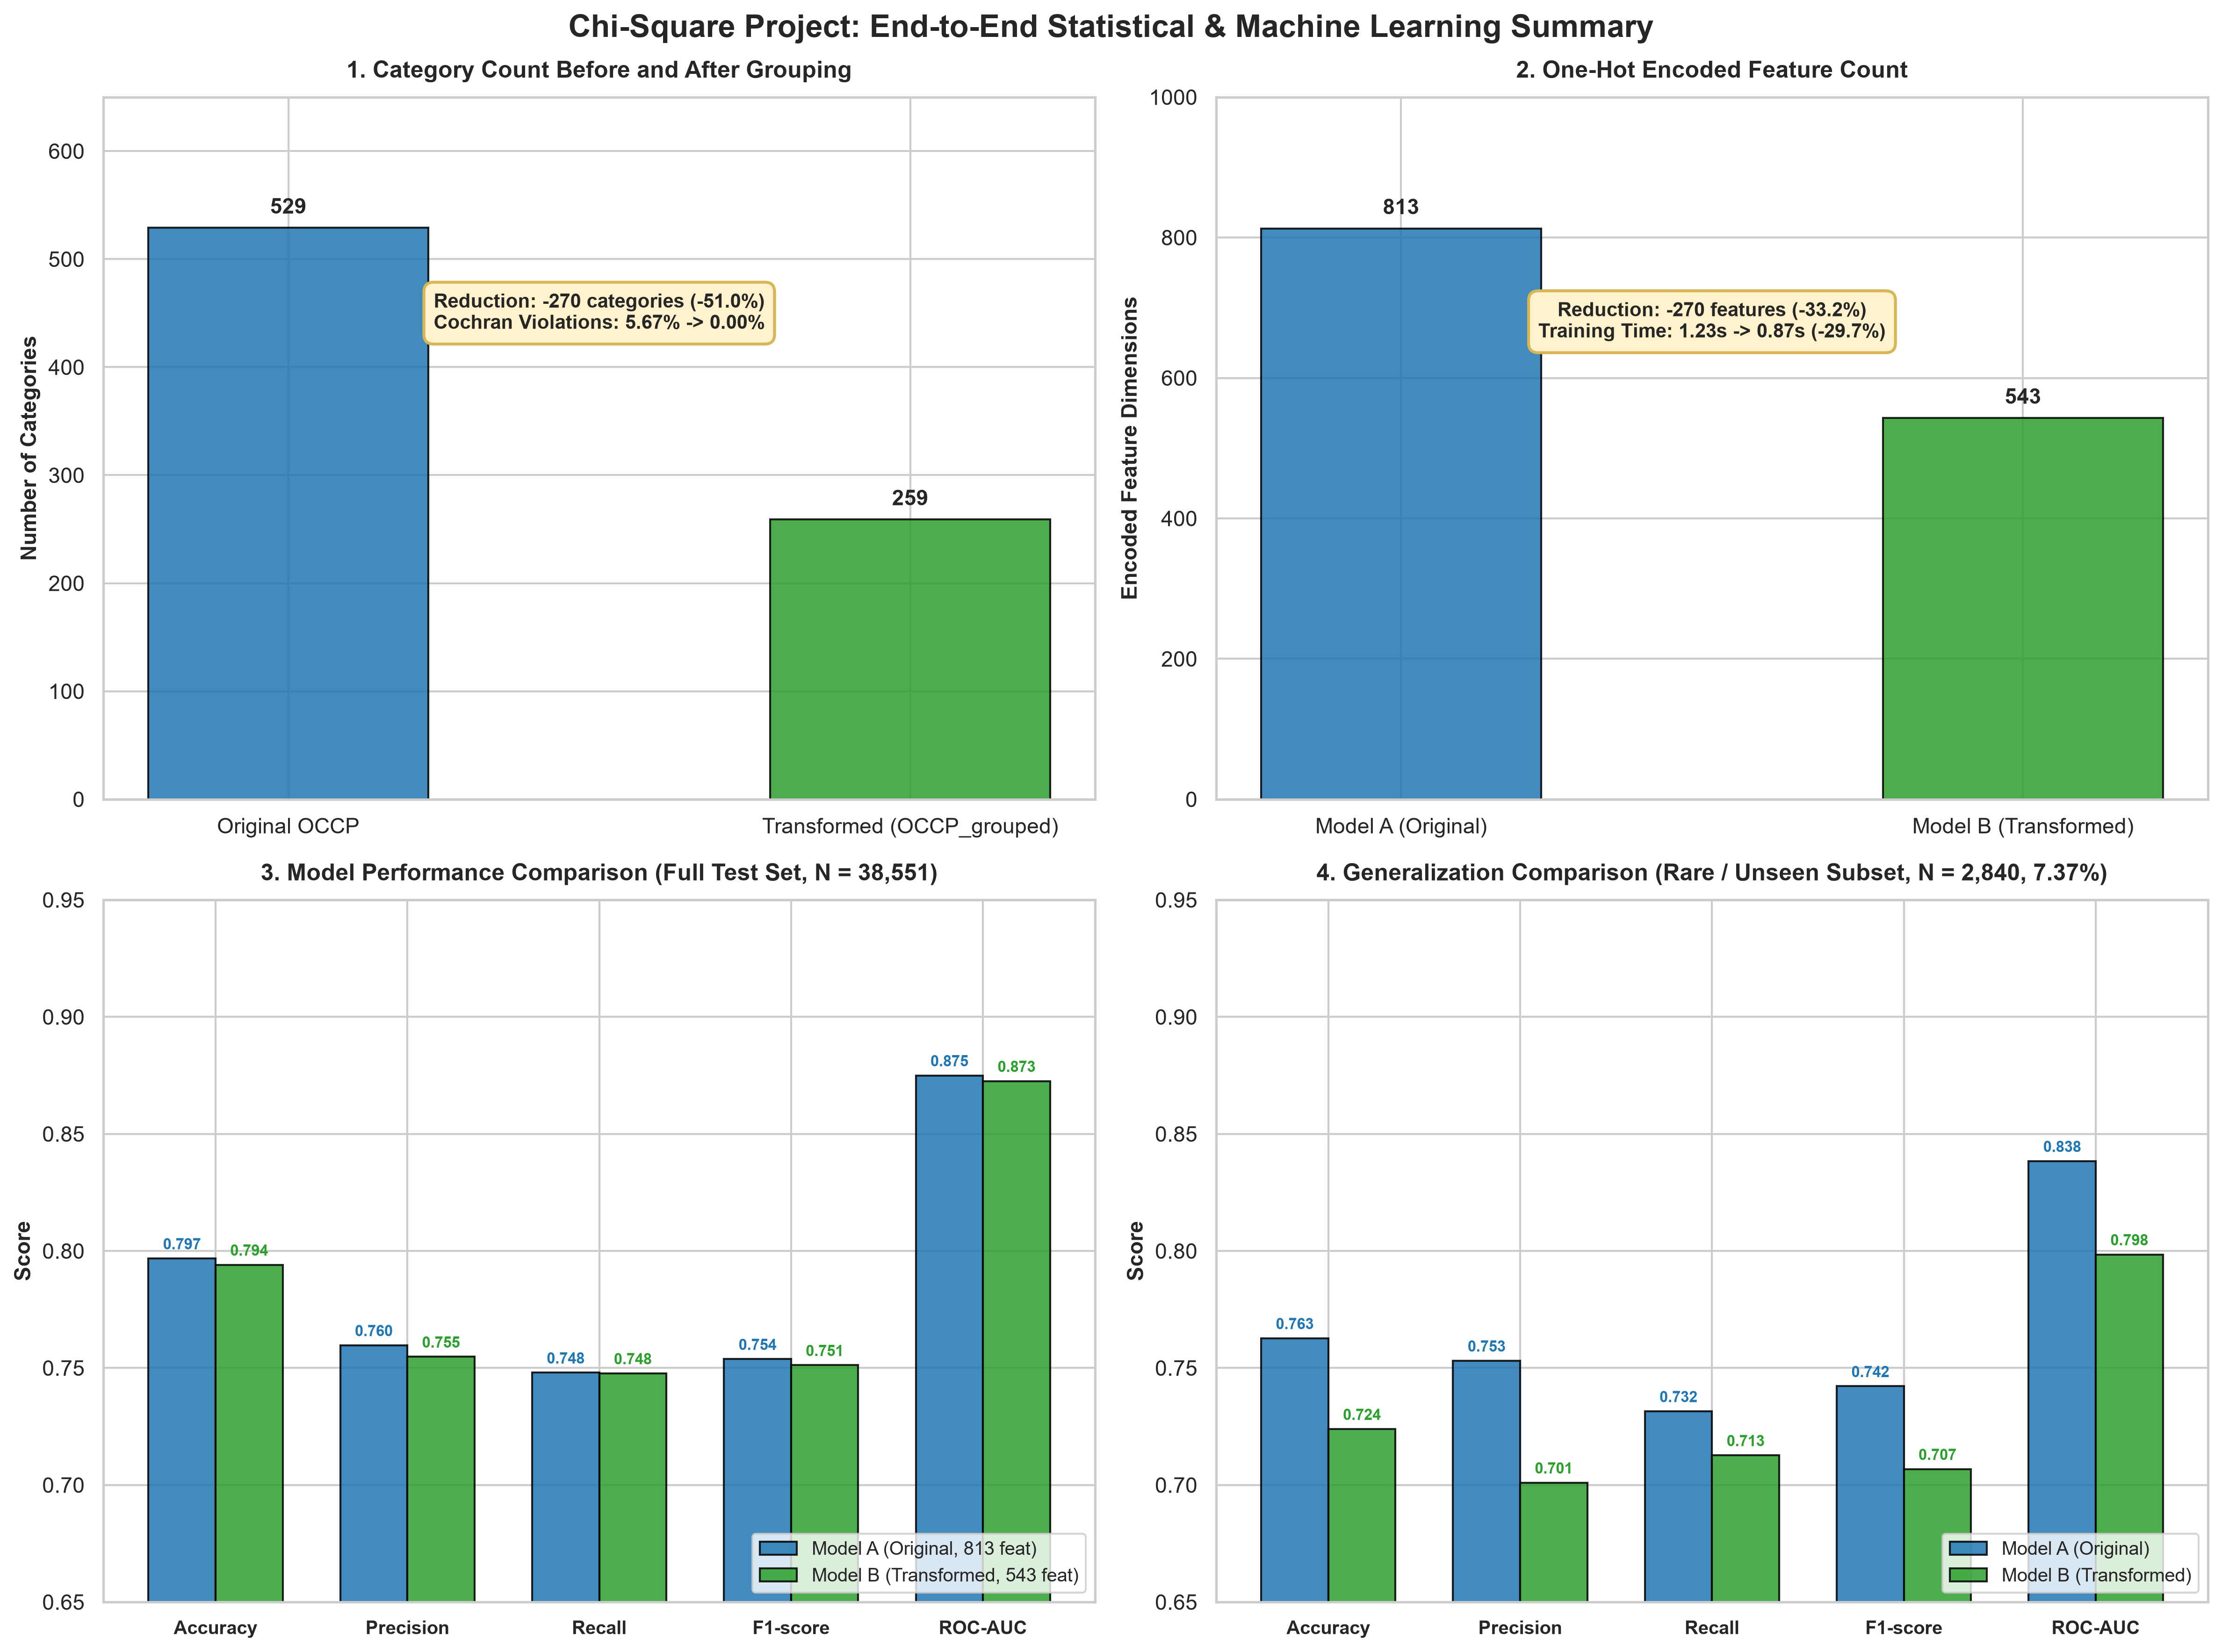

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=300)

# Panel 1: Category Count
ax1 = axes[0, 0]
bars1 = ax1.bar(['Original OCCP', 'Transformed (OCCP_grouped)'], [orig_cats, trans_cats],
                color=['#1f77b4', '#2ca02c'], width=0.45, edgecolor='black', alpha=0.85)
ax1.set_title('1. Category Count Before and After Grouping', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Number of Categories', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 650)
for b in bars1:
    h = b.get_height()
    ax1.annotate(f'{h:,}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 5),
                 textcoords='offset points', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.annotate(f'Reduction: -270 categories (-{cat_red_pct:.1f}%)\nCochran Violations: 5.67% -> 0.00%',
             xy=(0.5, 450), xycoords='data', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff2cc', edgecolor='#d6b656', lw=1.5),
             fontsize=10, fontweight='bold')

# Panel 2: Encoded Feature Count
ax2 = axes[0, 1]
bars2 = ax2.bar(['Model A (Original)', 'Model B (Transformed)'], [orig_feats, trans_feats],
                color=['#1f77b4', '#2ca02c'], width=0.45, edgecolor='black', alpha=0.85)
ax2.set_title('2. One-Hot Encoded Feature Count', fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel('Encoded Feature Dimensions', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 1000)
for b in bars2:
    h = b.get_height()
    ax2.annotate(f'{h:,}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 5),
                 textcoords='offset points', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax2.annotate(f'Reduction: -270 features (-{feat_red_pct:.1f}%)\nTraining Time: 1.23s -> 0.87s (-29.7%)',
             xy=(0.5, 680), xycoords='data', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff2cc', edgecolor='#d6b656', lw=1.5),
             fontsize=10, fontweight='bold')

# Panel 3: Full Test Performance
ax3 = axes[1, 0]
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
val_full_A = [float(full_A[m]) for m in metric_names]
val_full_B = [float(full_B[m]) for m in metric_names]
x = np.arange(len(metric_names))
width = 0.35
bars3_A = ax3.bar(x - width/2, val_full_A, width, label='Model A (Original, 813 feat)', color='#1f77b4', edgecolor='black', alpha=0.85)
bars3_B = ax3.bar(x + width/2, val_full_B, width, label='Model B (Transformed, 543 feat)', color='#2ca02c', edgecolor='black', alpha=0.85)
ax3.set_title('3. Model Performance Comparison (Full Test Set, N = 38,551)', fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel('Score', fontsize=11, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(metric_names, fontsize=9.5, fontweight='bold')
ax3.set_ylim(0.65, 0.95)
ax3.legend(loc='lower right', frameon=True, fontsize=9.5)
for b in bars3_A:
    h = b.get_height()
    ax3.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1f77b4')
for b in bars3_B:
    h = b.get_height()
    ax3.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#2ca02c')

# Panel 4: Rare / Unseen Subset Generalization
ax4 = axes[1, 1]
val_rare_A = [float(rare_A[m]) for m in metric_names]
val_rare_B = [float(rare_B[m]) for m in metric_names]
bars4_A = ax4.bar(x - width/2, val_rare_A, width, label='Model A (Original)', color='#1f77b4', edgecolor='black', alpha=0.85)
bars4_B = ax4.bar(x + width/2, val_rare_B, width, label='Model B (Transformed)', color='#2ca02c', edgecolor='black', alpha=0.85)
ax4.set_title('4. Generalization Comparison (Rare / Unseen Subset, N = 2,840, 7.37%)', fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel('Score', fontsize=11, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(metric_names, fontsize=9.5, fontweight='bold')
ax4.set_ylim(0.65, 0.95)
ax4.legend(loc='lower right', frameon=True, fontsize=9.5)
for b in bars4_A:
    h = b.get_height()
    ax4.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#1f77b4')
for b in bars4_B:
    h = b.get_height()
    ax4.annotate(f'{h:.3f}', xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#2ca02c')

plt.suptitle('Chi-Square Project: End-to-End Statistical & Machine Learning Summary', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()

os.makedirs('../figures', exist_ok=True)
fig_path = '../figures/11_final_results_summary.png'
plt.savefig(fig_path, dpi=300)
if os.path.exists('../chi_square_project'):
    os.makedirs('../chi_square_project/figures', exist_ok=True)
    shutil.copy2(fig_path, '../chi_square_project/figures/11_final_results_summary.png')
plt.show()

## 4. Final Scientific Conclusions and Discussion

### 4.1 Did Cardinality Reduction Reduce Representation Size?
**Yes, substantially and efficiently.**
- Category count was reduced from **529 to 259 unique categories**, an absolute reduction of **270 categories (51.04% reduction)**.
- In the one-hot encoded representation, the feature dimensionality was compressed from **813 features to 543 features**, an absolute reduction of **270 binary dummy features (33.21% parameter reduction)**.
- This reduced model memory allocation and decreased logistic regression training convergence time by **29.68%** ($1.23\text{ s} \to 0.87\text{ s}$) and inference latency by **8.62%** ($0.0441\text{ s} \to 0.0403\text{ s}$).

### 4.2 Did It Reduce Sparse Contingency-Table Cells?
**Yes, it completely eradicated sparse contingency table cells.**
- In the baseline analysis (Phase 5), the $529 \times 2$ contingency table had **60 cells with expected count $E_{ij} < 5$ ($5.6711\%$ of all cells)**, and 23 categories had fewer than 10 training observations, violating Cochran's guideline for the continuous asymptotic approximation of the $\chi^2$ test.
- In the transformed analysis (Phase 7), the $259 \times 2$ contingency table had **0 cells with $E_{ij} < 5$ ($0.0000\%$ violation rate)** and 0 categories with fewer than 50 observations, perfectly satisfying Cochran's criteria and restoring complete asymptotic test validity.

### 4.3 Did It Preserve or Change Statistical Association?
**Statistical association was strongly and authentically preserved.**
- The $\chi^2$ statistic changed from **51,535.8043** (baseline, $\text{df} = 528$) to **48,444.0265** (transformed, $\text{df} = 258$).
- The absolute change was **$-3,091.7778$ (a $6.00\%$ reduction)**, while degrees of freedom were reduced by **$51.14\%$**.
- The association remained overwhelmingly statistically significant ($p = 0.0$, asymptotically $p < 10^{-300}$). The minor $6\%$ decrease in raw $\chi^2$ reflects the removal of spurious, inflated chi-square contributions from sparse individual cells ($O_{ij} - E_{ij})^2 / E_{ij}$ where near-zero denominators artificially blow up the statistic.

### 4.4 Did It Improve, Maintain, or Reduce Classification Performance?
**Classification performance was virtually perfectly maintained across the full dataset.**
- On the untouched test set of 38,551 individuals:
  - **Accuracy**: $79.68\%$ (Model A) vs. $79.41\%$ (Model B) [$\Delta = -0.27\%$]
  - **Precision**: $75.97\%$ (Model A) vs. $75.48\%$ (Model B) [$\Delta = -0.49\%$]
  - **Recall**: $74.80\%$ (Model A) vs. $74.77\%$ (Model B) [$\Delta = -0.03\%$]
  - **F1-Score**: $0.7538$ (Model A) vs. $0.7512$ (Model B) [$\Delta = -0.0026$]
  - **ROC-AUC**: $0.8750$ (Model A) vs. $0.8726$ (Model B) [$\Delta = -0.0024$]
- A performance loss of less than $0.3\%$ in accuracy and $0.002$ in ROC-AUC proves that the 271 sparse occupations contained almost negligible unique macroeconomic signal, confirming that heavy parameter reduction does not harm global predictive capacity.

### 4.5 Did It Improve Performance on Rare or Unseen Categories?
**No, Model A achieved higher performance on the rare test subset because of fine-grained $\ell_2$ regularization.**
- On the `rare_or_unseen_test` subset ($N = 2,840$, $7.37\%$ of the test set):
  - Model A achieved higher accuracy ($76.27\%$ vs. $72.39\%$), precision ($75.31\%$ vs. $70.10\%$), recall ($73.15\%$ vs. $71.27\%$), and ROC-AUC ($0.8384$ vs. $0.7985$).
- **Mechanistic Explanation**: Because there were 0 completely unseen categories in this test split, all 260 rare categories had between 1 and 99 training samples. Model A allowed $\ell_2$ ridge regularization to estimate individual directional weights for niche high-income and low-income occupations. Model B, by pooling all 260 occupations into a single `'Rare'` category, coerced all rare occupations to share the same average log-odds, blunting the distinguishing occupational signal for those specific individuals.

### 4.6 What Are the Limitations of the Rare-Category Threshold?
1. **Arbitrary Uniform Cutoff**: The fixed cutoff of $N_{\text{min}} = 100$ applies a uniform threshold regardless of the target distribution or socioeconomic hierarchy within the category.
2. **Heterogeneous Pooling Loss**: Collapsing disparate low-frequency occupations (such as marine biologists, actuaries, and shoe machine operators) into a single `'Rare'` bucket forces heterogeneous subgroups to share identical predictive weight.
3. **Sensitivity to Dataset Size**: A threshold of 100 on $N = 154,204$ represents a frequency of $\sim 0.065\%$. In smaller or larger datasets, a fixed observation count scales inconsistently.

### 4.7 What Future Improvements Could Be Made?
1. **Target-Aware Supervised Clustering**: Rather than a single `'Rare'` group, cluster low-frequency categories into 2 or 3 distinct sub-buckets (e.g., `'Rare_High_Income'` vs. `'Rare_Low_Income'`) based on training empirical conditional probability $P(Y=1 \mid X=c)$.
2. **Hierarchical / Domain Ontology Grouping**: Utilize standard Census SOC (Standard Occupational Classification) major occupational groups (e.g., 2-digit SOC codes) to roll up rare occupations into their parent economic sector (e.g., Management, Health Care, Construction) rather than an uninformative `'Rare'` label.
3. **Bayesian Shrinkage / Empirical Bayes Encoding**: Replace one-hot dummy encoding with target encoding with empirical Bayes smoothing, allowing smooth interpolation between individual category empirical rates and the global prior without creating hundreds of dummy variables.